In [1]:
from pynq import Overlay, allocate
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import time

In [2]:
ol  = Overlay("image_p.bit")
dma = ol.axi_dma_0

### Carga de la imagen y reserva de buffers

In [5]:
img = np.array(Image.open("colors.jpg").convert("RGB"))
h, w, c = img.shape
n = img.size
print(f"Imagen: {w}x{h}, {n/1e6:.2f} MB")

Imagen: 800x600, 1.44 MB


In [6]:
in_buf  = allocate(shape=(n,), dtype=np.uint8)
out_buf = allocate(shape=(n,), dtype=np.uint8)

in_buf[:] = img.ravel()
in_buf.flush()

### Los dos filtros

In [7]:
def filtro_ps(img):
    out = img.copy()
    out[:, :, 0] = 255 - out[:, :, 0]
    return out

def filtro_pl(img):
    in_buf[:] = img.ravel()              # copia la imagen al buffer de la DMA
    in_buf.flush()
    t0 = time.perf_counter()
    dma.recvchannel.transfer(out_buf)    # primero se arma la recepción
    dma.sendchannel.transfer(in_buf)
    dma.sendchannel.wait()
    dma.recvchannel.wait()
    t_dma = time.perf_counter() - t0
    out_buf.invalidate()
    return np.array(out_buf).reshape(h, w, c), t_dma

`allocate` reserva memoria contigua en la DDR, que es la que la DMA puede leer y escribir. `flush()` asegura que los datos estén en la DDR y no solo en la caché del ARM.

### Benchmark mediante 20 corridas

In [8]:
N = 20
t_ps, t_pl, t_dma = [], [], []
for _ in range(N):
    t0 = time.perf_counter(); res_ps = filtro_ps(img)
    t_ps.append(time.perf_counter() - t0)

    t0 = time.perf_counter(); res_pl, td = filtro_pl(img)
    t_pl.append(time.perf_counter() - t0); t_dma.append(td)

ps = np.median(t_ps)  * 1e3
pl = np.median(t_pl)  * 1e3
dm = np.median(t_dma) * 1e3
print(f"PS (NumPy)  : {ps:7.2f} ms")
print(f"PL total    : {pl:7.2f} ms   speedup {ps/pl:.2f}x")
print(f"  solo DMA  : {dm:7.2f} ms   {n/dm/1e3:.1f} MB/s")
print("¿PL igual a PS?:", np.array_equal(res_pl, res_ps))

PS (NumPy)  :   20.21 ms
PL total    :   16.49 ms   speedup 1.23x
  solo DMA  :    2.68 ms   536.8 MB/s
¿PL igual a PS?: True


### Entrada y salidas lado a lado, más los tiempos

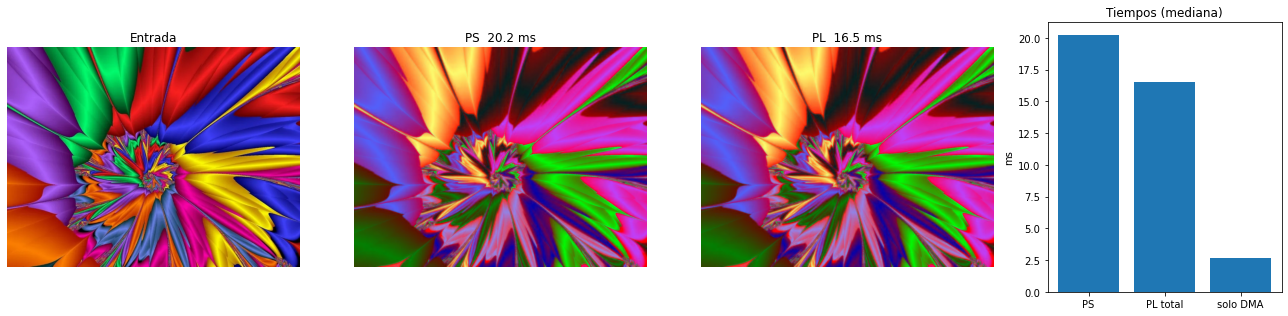

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5),
                       gridspec_kw={"width_ratios": [1, 1, 1, 0.8]})
for a, im, t in zip(ax[:3], [img, res_ps, res_pl],
                    ["Entrada", f"PS  {ps:.1f} ms", f"PL  {pl:.1f} ms"]):
    a.imshow(im); a.set_title(t); a.axis("off")

ax[3].bar(["PS", "PL total", "solo DMA"], [ps, pl, dm])
ax[3].set_ylabel("ms"); ax[3].set_title("Tiempos (mediana)")
plt.tight_layout(); plt.show()

In [10]:
in_buf.freebuffer(); out_buf.freebuffer()